# Modelagem preliminar — acompanhamento

Este notebook cobre **somente a etapa de acompanhamento**: compara o baseline pela média com um regressor `Ridge`, usando validação cruzada de três dobras no conjunto de desenvolvimento.

**O conjunto de teste não é lido nem avaliado aqui.** Também não são feitos busca de hiperparâmetros, PCA, balanceamento ou comparação de todas as famílias de modelos — esses itens pertencem às etapas posteriores do projeto.


In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, vstack

from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAIZ_PROJETO = Path.cwd()
if not (RAIZ_PROJETO / "dados").exists() and (RAIZ_PROJETO.parent / "dados").exists():
    RAIZ_PROJETO = RAIZ_PROJETO.parent

# Este notebook carrega somente desenvolvimento; o CSV de teste não é referenciado.
CAMINHO_DESENVOLVIMENTO = (
    RAIZ_PROJETO / "dados" / "processed" / "DADOS" / "desenvolvimento_80_numerico.csv"
)
ALVO = "NU_NOTA_MT"
COLUNA_ID = "NU_INSCRICAO"
TAMANHO_BLOCO = 100_000

if not CAMINHO_DESENVOLVIMENTO.exists():
    raise FileNotFoundError(
        f"Não encontrei {CAMINHO_DESENVOLVIMENTO}. Execute primeiro 03_limpeza_dados.ipynb."
    )

colunas_desenvolvimento = pd.read_csv(CAMINHO_DESENVOLVIMENTO, nrows=0).columns.tolist()
if ALVO not in colunas_desenvolvimento or COLUNA_ID not in colunas_desenvolvimento:
    raise KeyError("A base de desenvolvimento precisa conter NU_NOTA_MT e NU_INSCRICAO.")
FEATURES_NUMERICAS = [c for c in colunas_desenvolvimento if c not in {COLUNA_ID, ALVO}]

print(f"Arquivo de desenvolvimento: {CAMINHO_DESENVOLVIMENTO}")
print(f"Preditoras numéricas: {len(FEATURES_NUMERICAS)}")
print("O arquivo de teste não foi carregado.")


Arquivo de desenvolvimento: /Users/joaoigorandrade/Documents/unifor/cienciadedados/ciencia-de-dados-unifor-projeto-2/dados/processed/DADOS/desenvolvimento_80_numerico.csv
Preditoras numéricas: 138
O arquivo de teste não foi carregado.


## Carregar o desenvolvimento completo em formato esparso

A matriz numérica tem muitas colunas indicadoras 0/1. Ela é lida em blocos e armazenada como matriz esparsa para controlar a memória. São usados todos os registros do desenvolvimento, não uma amostra. O ID fica fora de `X`; `NU_NOTA_MT` é o alvo `y`.


In [2]:
blocos_X = []
blocos_y = []
linhas_carregadas = 0

for numero_bloco, bloco in enumerate(pd.read_csv(
    CAMINHO_DESENVOLVIMENTO,
    usecols=[*FEATURES_NUMERICAS, ALVO],
    dtype=np.float32,
    chunksize=TAMANHO_BLOCO,
), start=1):
    y_bloco = bloco[ALVO].to_numpy(dtype=np.float32, copy=True)
    if np.isnan(y_bloco).any():
        raise ValueError("Há nota-alvo ausente na partição de desenvolvimento.")
    X_bloco = csr_matrix(bloco[FEATURES_NUMERICAS].to_numpy(dtype=np.float32, copy=False))
    X_bloco.eliminate_zeros()
    blocos_X.append(X_bloco)
    blocos_y.append(y_bloco)
    linhas_carregadas += len(bloco)
    if numero_bloco % 5 == 0:
        print(f"Blocos lidos: {numero_bloco} | linhas: {linhas_carregadas:,}")

del bloco, X_bloco, y_bloco
gc.collect()
X_desenvolvimento = vstack(blocos_X, format="csr", dtype=np.float32)
y_desenvolvimento = np.concatenate(blocos_y).astype(np.float32, copy=False)
del blocos_X, blocos_y
gc.collect()

print(f"Registros no desenvolvimento: {X_desenvolvimento.shape[0]:,}")
print(f"Features usadas (ID excluído): {X_desenvolvimento.shape[1]}")
print(f"Elementos armazenados na matriz esparsa: {X_desenvolvimento.nnz:,}")
print(f"Nota média do desenvolvimento: {y_desenvolvimento.mean():.2f}")


Blocos lidos: 5 | linhas: 500,000


Blocos lidos: 10 | linhas: 1,000,000


Blocos lidos: 15 | linhas: 1,500,000


Blocos lidos: 20 | linhas: 2,000,000


Registros no desenvolvimento: 2,153,941
Features usadas (ID excluído): 138
Elementos armazenados na matriz esparsa: 43,899,831
Nota média do desenvolvimento: 533.83


## Protocolo da comparação

- Mesmas dobras para os dois modelos: `KFold(n_splits=3, shuffle=True, random_state=42)`.
- **Baseline:** `DummyRegressor(strategy="mean")`; em cada dobra, calcula a média apenas no treino daquela dobra.
- **Regressor preliminar:** `Ridge(alpha=1.0)`, com imputação pela mediana e padronização esparsa dentro do `Pipeline`, reajustadas em cada treino da dobra.
- Métricas: RMSE (principal), MAE e R²; também registramos o tempo de ajuste.

Os três folds são partições internas do desenvolvimento — **não são o conjunto de teste reservado**.


In [3]:
cv_acompanhamento = KFold(n_splits=3, shuffle=True, random_state=42)
scoring_acompanhamento = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

pipeline_ridge = Pipeline([
    ("imputacao", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("padronizacao", StandardScaler(with_mean=False)),
    ("modelo", Ridge(alpha=1.0, solver="lsqr")),
])

modelos_acompanhamento = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Ridge (alpha=1)": pipeline_ridge,
}

resultados_por_dobra = []
resumo_cv = []
for nome, modelo in modelos_acompanhamento.items():
    print(f"Executando validação cruzada: {nome}")
    resultado = cross_validate(
        modelo,
        X_desenvolvimento,
        y_desenvolvimento,
        cv=cv_acompanhamento,
        scoring=scoring_acompanhamento,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )
    for dobra in range(3):
        resultados_por_dobra.append({
            "modelo": nome,
            "dobra": dobra + 1,
            "RMSE": -resultado["test_rmse"][dobra],
            "MAE": -resultado["test_mae"][dobra],
            "R²": resultado["test_r2"][dobra],
            "tempo_ajuste_seg": resultado["fit_time"][dobra],
        })
    resumo_cv.append({
        "modelo": nome,
        "RMSE_medio": -resultado["test_rmse"].mean(),
        "RMSE_dp": resultado["test_rmse"].std(ddof=1),
        "MAE_medio": -resultado["test_mae"].mean(),
        "MAE_dp": resultado["test_mae"].std(ddof=1),
        "R2_medio": resultado["test_r2"].mean(),
        "R2_dp": resultado["test_r2"].std(ddof=1),
        "tempo_ajuste_total_seg": resultado["fit_time"].sum(),
    })

df_resultados_dobras = pd.DataFrame(resultados_por_dobra)
df_resumo_cv = pd.DataFrame(resumo_cv).sort_values("RMSE_medio").reset_index(drop=True)
print("Resultados por dobra (todas no desenvolvimento):")
display(df_resultados_dobras)
print("Resumo: média e desvio padrão entre as três dobras:")
display(df_resumo_cv)


Executando validação cruzada: Baseline (média)


Executando validação cruzada: Ridge (alpha=1)


Resultados por dobra (todas no desenvolvimento):


,modelo,dobra,RMSE,MAE,R²,tempo_ajuste_seg
0,Baseline (média),1,131.517120,107.549866,-2.384186e-07,0.071520
1,Baseline (média),2,131.571701,107.546303,-4.768372e-06,0.042616
2,Baseline (média),3,131.813522,107.649147,-6.794930e-06,0.030543
3,Ridge (alpha=1),1,110.542824,86.604698,2.935254e-01,1.584915
4,Ridge (alpha=1),2,110.548668,86.543114,2.940333e-01,1.399078
5,Ridge (alpha=1),3,110.848373,86.656487,2.928008e-01,1.392860


Resumo: média e desvio padrão entre as três dobras:


,modelo,RMSE_medio,RMSE_dp,MAE_medio,MAE_dp,R2_medio,R2_dp,tempo_ajuste_total_seg
0,Ridge (alpha=1),110.646622,0.174747,86.601433,0.056757,0.293453,0.000619,4.376853
1,Baseline (média),131.634115,0.157750,107.581772,0.058376,-0.000004,0.000003,0.144679


## Comparação visual e leitura inicial

RMSE e MAE estão na escala original da nota; valores menores indicam erros médios menores. R² compara o ajuste com a variação da nota e pode ser negativo. Uma diferença pequena entre dobras deve ser interpretada com cautela.


In [4]:
import plotly.express as px

fig_rmse_dobras = px.bar(
    df_resultados_dobras,
    x="dobra",
    y="RMSE",
    color="modelo",
    barmode="group",
    title="Acompanhamento: RMSE por dobra de validação",
    labels={"dobra": "Dobra no desenvolvimento", "RMSE": "RMSE (pontos da nota)"},
    text_auto=".1f",
)
fig_rmse_dobras.update_layout(template="plotly_white")
fig_rmse_dobras.show()

melhor_preliminar = df_resumo_cv.iloc[0]
print(
    f"Menor RMSE médio preliminar: {melhor_preliminar['modelo']} "
    f"({melhor_preliminar['RMSE_medio']:.2f} ± {melhor_preliminar['RMSE_dp']:.2f})."
)
print("Este resultado usa somente validação cruzada no desenvolvimento; o teste continua intocado.")


Menor RMSE médio preliminar: Ridge (alpha=1) (110.65 ± 0.17).
Este resultado usa somente validação cruzada no desenvolvimento; o teste continua intocado.


## Para apresentar no acompanhamento

Na execução local atual, no desenvolvimento completo: baseline RMSE **131,63 ± 0,16**, MAE **107,58 ± 0,06**, R² **≈ 0**; Ridge RMSE **110,65 ± 0,17**, MAE **86,60 ± 0,06**, R² **0,293**. Reexecute as células para atualizar estes valores.

Incluam a tabela de métricas e o gráfico, expliquem se o Ridge melhorou em relação ao baseline e comentem a variação entre as dobras. Esta é uma comparação **preliminar**; não significa que o Ridge já seja o modelo final. Não escolham o modelo final pelo conjunto de teste nesta etapa.


## Como o Ridge está prevendo (gráficos da regressão)

A tabela e as barras acima resumem o erro. Aqui está **a previsão em si**, para uma dobra de validação do desenvolvimento (treino em duas dobras, validação na terceira; o teste não é lido):

1. **Previsão × observado:** cada célula agrupa participantes; a linha vermelha tracejada é a previsão perfeita e a laranja é a nota prevista média em cada faixa de nota observada.
2. **Resíduos × previsão:** resíduo = observado − previsto. Serve para procurar padrões nos erros.
3. **Maiores pesos do Ridge:** quais features mais puxam a nota prevista para cima (verde) ou para baixo (vermelho). Os pesos são das features padronizadas, então são comparáveis entre si. Nas variáveis dummy o peso é **em relação à categoria de referência**, e a associação não indica causalidade.

Treino: 1,435,960 | validação: 717,981
Ridge (alpha=1): RMSE 110.54 | MAE 86.60 | R² 0.294 | baseline RMSE 131.52
Previsão média para as notas zero: 515 pontos (n=4,356)


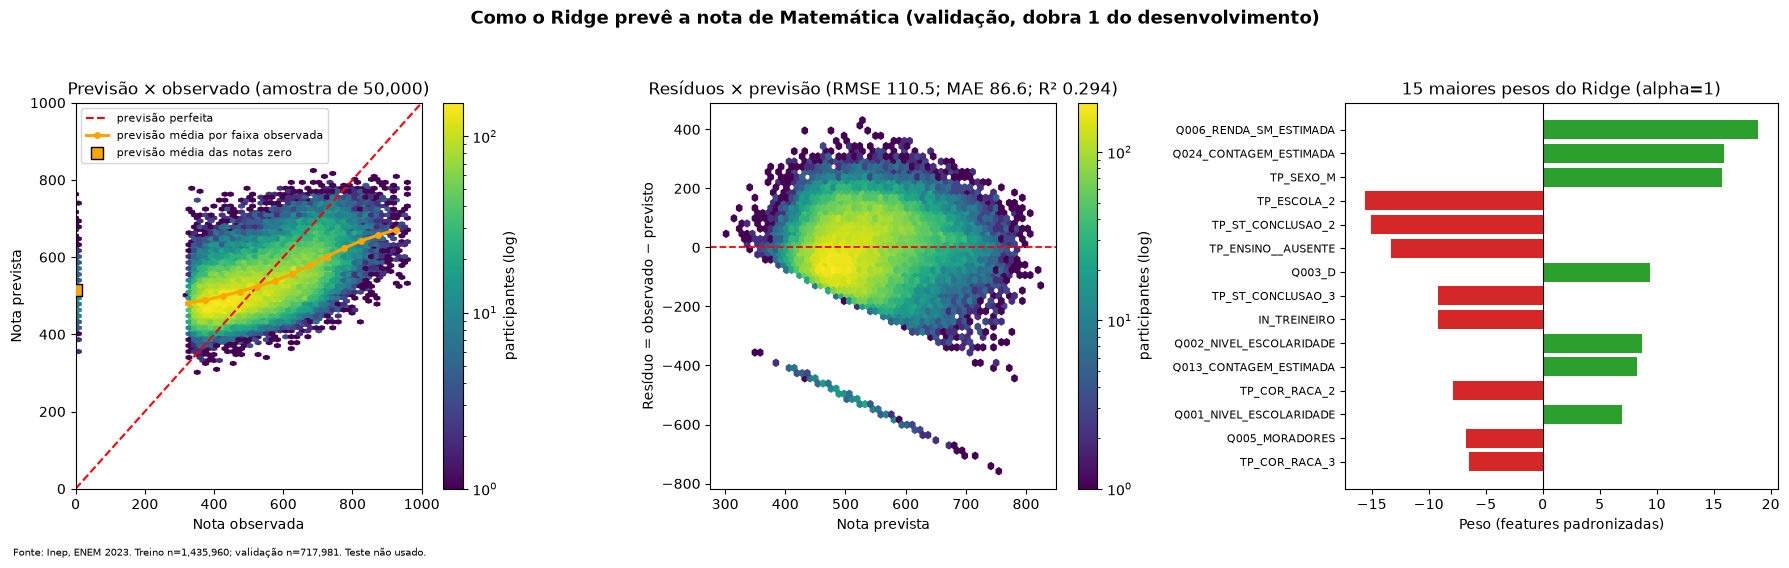

In [5]:
import sys

sys.path.insert(0, str(RAIZ_PROJETO / "src"))
%matplotlib inline
from IPython.display import display
import matplotlib.pyplot as plt
from ajuste_interativo import painel, plotar_previsoes, separar_dobra, treinar_e_avaliar

# Reaproveita X_desenvolvimento e y_desenvolvimento, já carregados acima (nenhuma leitura nova).
dobra_interativa = separar_dobra(X_desenvolvimento, y_desenvolvimento)
resultado_ridge = treinar_e_avaliar(1.0, dobra_interativa)
print(f"Treino: {len(dobra_interativa.y_tr):,} | validação: {len(dobra_interativa.y_va):,}")
print(f"Ridge (alpha=1): RMSE {resultado_ridge['rmse']:.2f} | MAE {resultado_ridge['mae']:.2f} | "
      f"R² {resultado_ridge['r2']:.3f} | baseline RMSE {dobra_interativa.rmse_baseline:.2f}")
zeros = dobra_interativa.y_va == 0
print(f"Previsão média para as notas zero: {resultado_ridge['previsao'][zeros].mean():.0f} pontos "
      f"(n={int(zeros.sum()):,})")

figura_previsoes = plotar_previsoes(resultado_ridge, dobra_interativa, FEATURES_NUMERICAS)
pasta_figuras = RAIZ_PROJETO / "resultados" / "figuras"
pasta_figuras.mkdir(parents=True, exist_ok=True)
figura_previsoes.savefig(pasta_figuras / "acompanhamento_previsoes_ridge.png", dpi=150)
display(figura_previsoes)
plt.close(figura_previsoes)

### Leitura inicial

- **As previsões são "achatadas" em direção à média.** A linha laranja sobe com a nota observada, mas bem menos que a linha de previsão perfeita: quem tirou nota baixa tende a ser previsto acima do real, e quem tirou nota alta, abaixo. O perfil socioeconômico e escolar separa os participantes só em parte (R² ≈ 0,29).
- **Notas zero:** o modelo prevê para elas valores próximos do restante (ver o número impresso acima), e por isso formam a faixa diagonal de resíduos muito negativos no gráfico do meio (resíduo = −previsão). Não conseguimos identificar esses casos só pelo perfil.
- **Pesos:** renda (`Q006`), computador em casa (`Q024`) e escolaridade dos responsáveis aparecem entre os que elevam a nota prevista; escola pública (`TP_ESCOLA_2`, em relação à categoria "não respondeu") e a situação de conclusão do ensino médio puxam para baixo. São associações, e não efeitos causais.

## Previsão × observado de cada modelo (todos os dados)

Uma célula por modelo, cada uma com seus **próprios parâmetros e features**, declarados no topo (`PARAMETROS` e `FEATURES`) e impressos na saída junto com todos os parâmetros do estimador.

O gráfico mostra **todos os participantes do desenvolvimento**, sem amostra. Cada ponto é a nota observada contra a nota prevista por um modelo que **não viu aquele participante no treino** (`cross_val_predict`, com o mesmo `KFold(n_splits=3, shuffle=True, random_state=42)` do protocolo). São mais de 2 milhões de pontos, então eles são agrupados em hexágonos e a cor mostra quantos participantes caem em cada um (escala logarítmica).

**Painel da esquerda (previsão × observado):**
- **Linha vermelha tracejada:** a linha ideal (previsto = observado).
- **Linha laranja:** reta de regressão do previsto sobre o observado. Inclinação 1 quer dizer que o modelo acompanha a nota; inclinação menor que 1 quer dizer previsões "achatadas" em direção à média; inclinação 0 é o modelo que sempre prevê o mesmo valor.
- **Pontos pretos com traço vertical:** 40 participantes sorteados. O traço é o **erro** de cada um, a distância vertical do ponto até a linha ideal.

**Painel da direita (distribuição dos erros):** o histograma dos erros (observado − previsto) de todos os participantes. O **MAE** é a média dessas distâncias, ou seja, a distância vertical média dos pontos até a linha ideal. O **RMSE** dá mais peso aos erros grandes. As linhas tracejadas marcam ± MAE e ± RMSE.

As métricas do quadro são agregadas nas três dobras, então diferem um pouco da média das dobras da tabela acima.

Para testar outros parâmetros ou outro conjunto de features, copie uma célula e mude `PARAMETROS` e `FEATURES`. **O conjunto de teste não é lido.**

In [ ]:
import sys

sys.path.insert(0, str(RAIZ_PROJETO / "src"))
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from grafico_regressao import avaliar_modelo

PASTA_FIGURAS = RAIZ_PROJETO / "resultados" / "figuras"

Modelo: Baseline (média)
Parâmetros declarados: {'strategy': 'mean'}
Features: nenhuma (o modelo ignora X)
Todos os parâmetros do estimador final (DummyRegressor): {'constant': None, 'quantile': None, 'strategy': 'mean'}
Matriz usada: 2,153,941 linhas × 138 colunas


RMSE 131.63 | MAE 107.58 | R² -0.0000 | reta: previsto = 533.8 + (-0.000) × observado (agregado das 3 dobras)


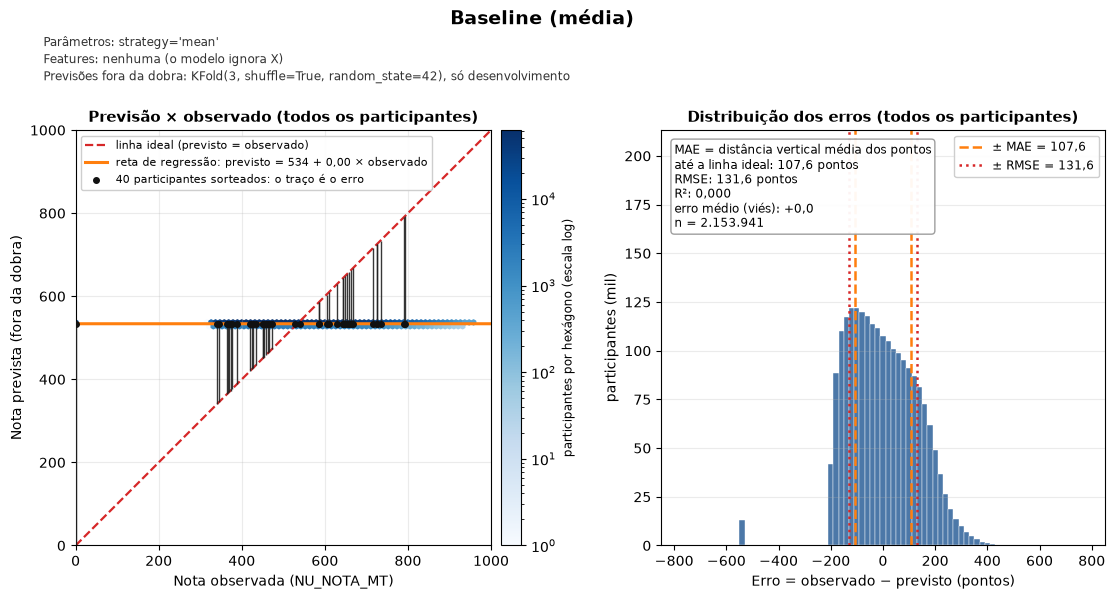

In [ ]:
# ---- Modelo 1: baseline pela média ------------------------------------------------------------
NOME_MODELO = "Baseline (média)"
PARAMETROS = {"strategy": "mean"}
FEATURES = []   # o baseline ignora X: nenhuma feature entra na previsão

modelo = DummyRegressor(**PARAMETROS)
resultado_baseline = avaliar_modelo(
    NOME_MODELO, modelo, PARAMETROS, FEATURES,
    X_desenvolvimento, y_desenvolvimento, FEATURES_NUMERICAS,
    pasta_figuras=PASTA_FIGURAS,
)
display(resultado_baseline["figura"])
plt.close(resultado_baseline["figura"])

Modelo: Ridge (alpha=1)
Parâmetros declarados: {'alpha': 1.0, 'solver': 'lsqr'}
Preparação: imputação pela mediana + padronização esparsa (StandardScaler com with_mean=False), reajustadas no treino de cada dobra
Features: 138 de 138 colunas: TP_FAIXA_ETARIA_2, TP_FAIXA_ETARIA_3, TP_FAIXA_ETARIA_4, TP_FAIXA_ETARIA_5 … (+134)
Todos os parâmetros do estimador final (Ridge): {'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'lsqr', 'tol': 0.0001}
Matriz usada: 2,153,941 linhas × 138 colunas


RMSE 110.65 | MAE 86.60 | R² 0.2935 | reta: previsto = 377.2 + (0.293) × observado (agregado das 3 dobras)


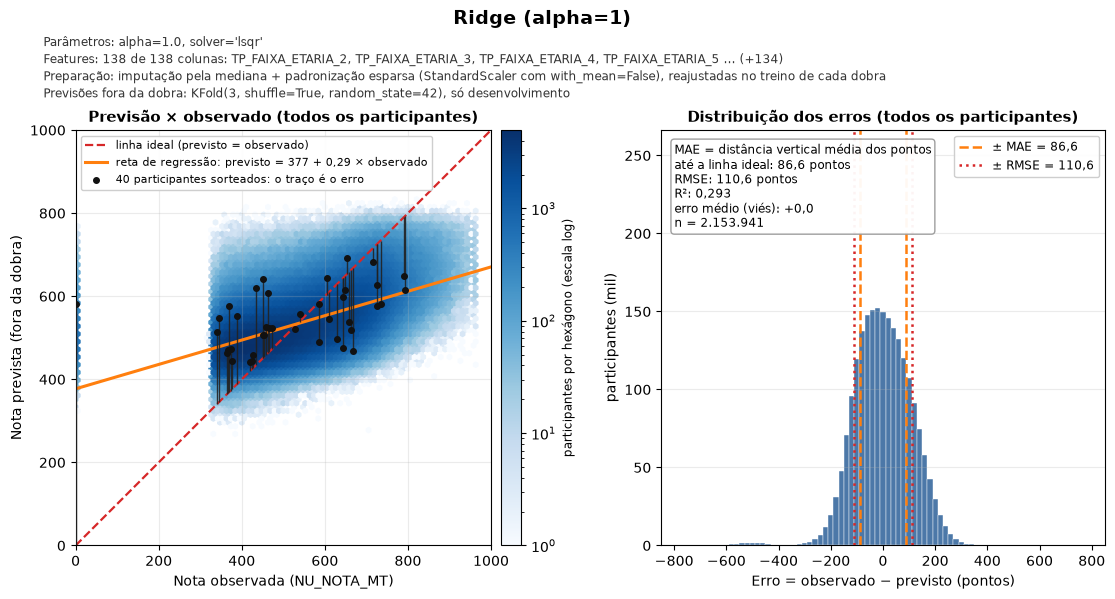

Previsões do Ridge: de 264 a 831 (percentis 1% e 99%: 405 e 728); nota observada: de 0 a 959
Previsão média para as 13,300 notas zero: 515 pontos


In [ ]:
# ---- Modelo 2: Ridge ----------------------------------------------------------------------------
NOME_MODELO = "Ridge (alpha=1)"
PARAMETROS = {"alpha": 1.0, "solver": "lsqr"}
PREPARACAO = "imputação pela mediana + padronização esparsa (StandardScaler com with_mean=False), reajustadas no treino de cada dobra"
FEATURES = FEATURES_NUMERICAS   # as 138 colunas; para testar outro conjunto, troque por uma lista menor de nomes

modelo = Pipeline([
    ("imputacao", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("padronizacao", StandardScaler(with_mean=False)),
    ("modelo", Ridge(**PARAMETROS)),
])
resultado_ridge_todos = avaliar_modelo(
    NOME_MODELO, modelo, PARAMETROS, FEATURES,
    X_desenvolvimento, y_desenvolvimento, FEATURES_NUMERICAS,
    preparacao=PREPARACAO, pasta_figuras=PASTA_FIGURAS,
)
display(resultado_ridge_todos["figura"])
plt.close(resultado_ridge_todos["figura"])

previsao_ridge = resultado_ridge_todos["previsao"]
zeros = y_desenvolvimento == 0
print(f"Previsões do Ridge: de {previsao_ridge.min():.0f} a {previsao_ridge.max():.0f} "
      f"(percentis 1% e 99%: {np.percentile(previsao_ridge, 1):.0f} e {np.percentile(previsao_ridge, 99):.0f}); "
      f"nota observada: de {y_desenvolvimento.min():.0f} a {y_desenvolvimento.max():.0f}")
print(f"Previsão média para as {int(zeros.sum()):,} notas zero: {previsao_ridge[zeros].mean():.0f} pontos")

### Leitura dos dois gráficos

- **Baseline (média):** a reta de regressão é **horizontal em 534 pontos** (a média da nota no desenvolvimento) e tem inclinação 0. O modelo dá a mesma previsão a todos, então os pontos formam uma faixa plana. RMSE 131,6 e R² 0, que é o erro de referência.
- **Ridge:** a reta sobe, mas com **inclinação 0,29**, bem abaixo da diagonal (inclinação 1). Cada 100 pontos de nota observada a mais correspondem, em média, a só 29 pontos a mais na previsão. A inclinação aqui coincide com o R² (0,293 e 0,2935). RMSE 110,6, cerca de 16% menor que o do baseline.
- **As previsões são achatadas.** O Ridge prevê entre 264 e 831 pontos (a maioria, entre 405 e 728), enquanto a nota observada vai de 0 a 959. Quem tirou nota baixa tende a ser previsto acima do real, e quem tirou nota alta, abaixo.
- **Notas zero:** são a coluna isolada à esquerda (13.300 participantes). O Ridge prevê em média **515 pontos** para elas, como se fossem participantes comuns. O perfil socioeconômico não separa esses casos.
- **Limite:** o perfil explica parte da variação (R² 0,29), e uma nuvem larga em torno da reta mostra que há muita variação que as features não capturam. Os valores são de validação cruzada no desenvolvimento, com `alpha` fixo e sem busca de hiperparâmetros; o teste continua intocado.

## Cada modelo em cada conjunto de features

Cada modelo é treinado nos **mesmos três conjuntos de features**, com as mesmas dobras (`KFold(3, shuffle=True, random_state=42)`, só desenvolvimento). Uma célula por modelo, com os parâmetros declarados no topo:

- **A:** todas as features originais depois do tratamento (138 colunas).
- **B:** A mais 5 features derivadas calculadas a partir das originais (143 colunas).
- **D:** B com os grupos redundantes fundidos (140 colunas): as originais sem relação ficam, e as colunas correlacionadas entre si (renda e escolaridade) viram duas colunas fundidas. A fusão fica **dentro do `Pipeline`, antes do modelo**, e aprende a média e o desvio só no treino de cada dobra.

O baseline pela média **não usa features**, então o resultado dele é o mesmo nos três conjuntos; ele entra na comparação por completude. Para incluir outro modelo, copie uma célula e mude `PARAMETROS` e a função que cria o estimador.

In [ ]:
import sys

sys.path.insert(0, str(RAIZ_PROJETO / "src"))
from conjuntos_features import CONJUNTOS, avaliar_nos_conjuntos, montar_conjunto

CV_CONJUNTOS = KFold(n_splits=3, shuffle=True, random_state=42)
SCORING_CONJUNTOS = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
# A matriz de cada conjunto é montada uma vez; em D a fusão acontece dentro do Pipeline, em cada dobra.
MATRIZES = {conjunto: montar_conjunto(conjunto, X_desenvolvimento, FEATURES_NUMERICAS) for conjunto in CONJUNTOS}
for conjunto, descricao in CONJUNTOS.items():
    print(f"{conjunto}: {descricao}")

A: Originais tratadas (138 colunas)
B: A + 5 derivadas (143 colunas)
D: B com os grupos redundantes fundidos (140 colunas)


In [ ]:
# ---- Modelo 1: baseline pela média, nos conjuntos A, B e D ---------------------------------------
NOME_MODELO = "Baseline (média)"
PARAMETROS = {"strategy": "mean"}
CONJUNTOS_USADOS = ["A", "B", "D"]   # troque para testar outros conjuntos

tabela_baseline = avaliar_nos_conjuntos(
    NOME_MODELO, lambda: DummyRegressor(**PARAMETROS), PARAMETROS, CONJUNTOS_USADOS, MATRIZES,
    y_desenvolvimento, CV_CONJUNTOS, SCORING_CONJUNTOS, preparar=False,   # o baseline ignora as features
)
display(tabela_baseline)

Modelo: Baseline (média)
Parâmetros declarados: {'strategy': 'mean'}
Todos os parâmetros do estimador: {'constant': None, 'quantile': None, 'strategy': 'mean'}


,conjunto,colunas,RMSE,MAE,R²,tempo_ajuste_s
0,A,138,131.634 ± 0.158,107.582 ± 0.058,-0.0000 ± 0.0000,0.1
1,B,143,131.634 ± 0.158,107.582 ± 0.058,-0.0000 ± 0.0000,0.1
2,D,140,131.634 ± 0.158,107.582 ± 0.058,-0.0000 ± 0.0000,0.1


In [ ]:
# ---- Modelo 2: Ridge, nos conjuntos A, B e D -----------------------------------------------------
NOME_MODELO = "Ridge (alpha=1)"
PARAMETROS = {"alpha": 1.0, "solver": "lsqr"}
CONJUNTOS_USADOS = ["A", "B", "D"]   # troque para testar outros conjuntos
# Preparação (dentro do Pipeline, por dobra): imputação pela mediana, fusão (só em D) e padronização esparsa.

tabela_ridge = avaliar_nos_conjuntos(
    NOME_MODELO, lambda: Ridge(**PARAMETROS), PARAMETROS, CONJUNTOS_USADOS, MATRIZES,
    y_desenvolvimento, CV_CONJUNTOS, SCORING_CONJUNTOS, preparar=True,
)
display(tabela_ridge)

Modelo: Ridge (alpha=1)
Parâmetros declarados: {'alpha': 1.0, 'solver': 'lsqr'}
Todos os parâmetros do estimador: {'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'lsqr', 'tol': 0.0001}


,conjunto,colunas,RMSE,MAE,R²,tempo_ajuste_s
0,A,138,110.647 ± 0.175,86.601 ± 0.057,0.2935 ± 0.0006,4.8
1,B,143,110.447 ± 0.179,86.383 ± 0.057,0.2960 ± 0.0007,6.9
2,D,140,110.553 ± 0.172,86.503 ± 0.050,0.2947 ± 0.0006,6.9


### Leitura da comparação entre conjuntos

- **Baseline:** RMSE 131,634 nos três conjuntos, como esperado, porque ele ignora as features.
- **Ridge:** o conjunto **B** (originais + 5 derivadas) é o melhor, com RMSE 110,447 e R² 0,2960, cerca de 0,2 ponto abaixo do A (110,647). O conjunto **D** (com a fusão) fica no meio, com 110,553: perde parte do ganho das derivadas, mas usa 3 colunas a menos que o B.
- Os valores reproduzem os já registrados em `resultados/experimentos.csv` (`feat_A`, `feat_B` e `feat_D`). A tabela completa está em `resultados/tabelas/modelos_por_conjunto.csv` (gerada por `src/modelos_por_conjunto.py`).
- Validação cruzada no desenvolvimento, com `alpha` fixo e sem busca de hiperparâmetros; o teste continua intocado.

## Ajuste interativo (exploração)

Escolha o **modelo**, arraste os **hiperparâmetros** e a quantidade de **linhas de treino**. Ao soltar o controle, o modelo é treinado de novo e os quatro gráficos são atualizados.

| Modelo | Controles |
|---|---|
| Ridge | `alpha` (escala logarítmica, 0,001 a 100 milhões) |
| Árvore de decisão | `max_depth`, `min_samples_leaf` |
| Gradient Boosting | `max_iter`, `learning_rate`, `max_depth` |

- Árvore e boosting começam com **200 mil linhas de treino** para responder rápido; aumente o controle "Linhas de treino" para usar mais. O Ridge começa com todas.
- O treino usa a mesma divisão da seção anterior (duas dobras para treino, uma para validação). **O teste continua sem ser lido.**
- É uma **exploração**, não a busca de hiperparâmetros: a escolha oficial será feita depois, por validação cruzada (`GridSearchCV` / `RandomizedSearchCV`).
- "Limpar histórico" zera o gráfico das tentativas.

> Os gráficos aparecem depois que você roda a célula abaixo, com o kernel do `.venv` (onde o `ipywidgets` está instalado: `pip install -r requirements.txt`). Só com o arquivo aberto, sem rodar, o controle não aparece.

In [6]:
painel(dobra_interativa)

### O que observar no painel

1. **Previsão × observado:** quanto mais perto da linha vermelha, melhor.
2. **Resíduos** (observado − previsto): o ideal é centrado em zero e estreito.
3. **Erro por faixa de nota:** onde o modelo erra mais, comparado ao baseline.
4. **RMSE de cada tentativa:** a cor indica o modelo; a linha tracejada é o baseline.

Algumas coisas para testar:

- **Ridge:** entre `alpha` ≈ 0,001 e alguns milhares o RMSE quase **não muda** (com milhões de linhas e 138 colunas a regularização pesa pouco). Só acima de ≈ 10⁶ o modelo é freado demais e o erro volta para perto do baseline (subajuste).
- **Árvore:** com `max_depth` pequeno o erro é alto (subajuste); aumentar a profundidade melhora, até certo ponto.
- **Gradient Boosting:** em um teste com a dobra 1, o boosting com **200 mil linhas** (RMSE ≈ 108,9) já ficou **abaixo do Ridge com todas as linhas** (≈ 110,5). Isso é uma pista, e não uma conclusão: foi uma única dobra, e a comparação oficial usa a validação cruzada completa.
- **Linhas de treino:** veja como o erro muda quando o treino cresce; isso antecipa a curva de aprendizado exigida no projeto.